# Análisis de residuos — ajuste y diagnóstico
**Objetivo:** elegir modelos observando los datos **y** los residuos: $r_i=y_i-f(x_i)$. Se conserva la secuencia de tres ejemplos del notebook de clase.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
plt.style.use('bmh')

def graficar_ajuste(x, y, modelo, titulo):
    xx = np.linspace(x.min(), x.max(), 300)
    residuos = y - modelo(x)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
    ax1.scatter(x, y, s=18, label='Datos')
    ax1.plot(xx, modelo(xx), label='Modelo')
    ax1.set(ylabel='y', title=titulo)
    ax1.legend()
    ax2.scatter(x, residuos, s=18)
    ax2.axhline(0, c='black', ls='--', lw=1)
    ax2.set(xlabel='x', ylabel='Residuo')
    plt.tight_layout(); plt.show()
    return residuos

## 1. Ejemplo A — recta con residuos sin tendencia evidente
El ajuste lineal minimiza la suma de los residuos al cuadrado. Que la media de los residuos sea casi cero no demuestra por sí solo que el modelo sea correcto.

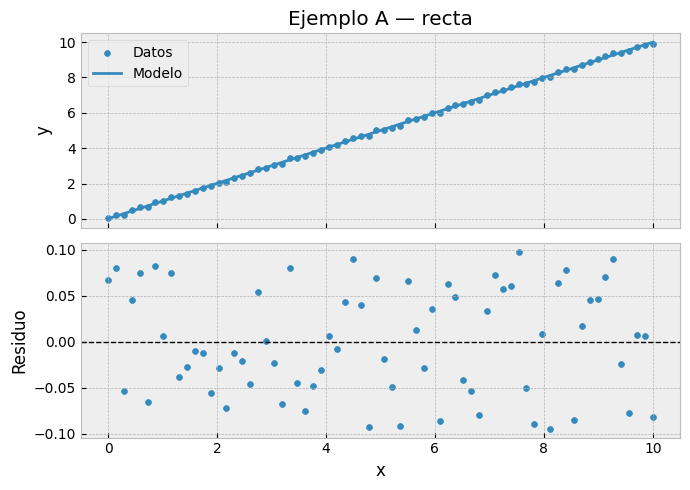

Media de residuos: 1.9123591599168323e-15


In [2]:
x1, y1 = np.genfromtxt('ejemplo-s11a.txt').T
a1, a0 = np.polyfit(x1, y1, 1)
res1 = graficar_ajuste(x1, y1, lambda z: a1*z + a0, 'Ejemplo A — recta')
print('Media de residuos:', np.mean(res1))

## 2. Ejemplo B — residuos curvos
Una tendencia curvada en los residuos revela estructura que la recta no captura. Comparamos grado 1 frente a grado 2 usando **los mismos datos**.

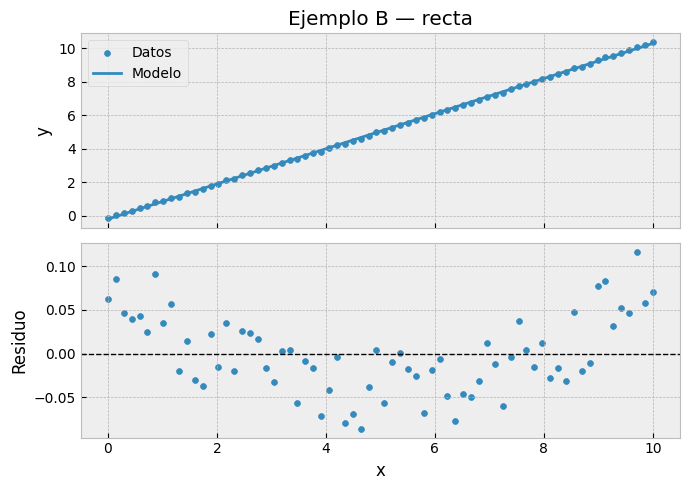

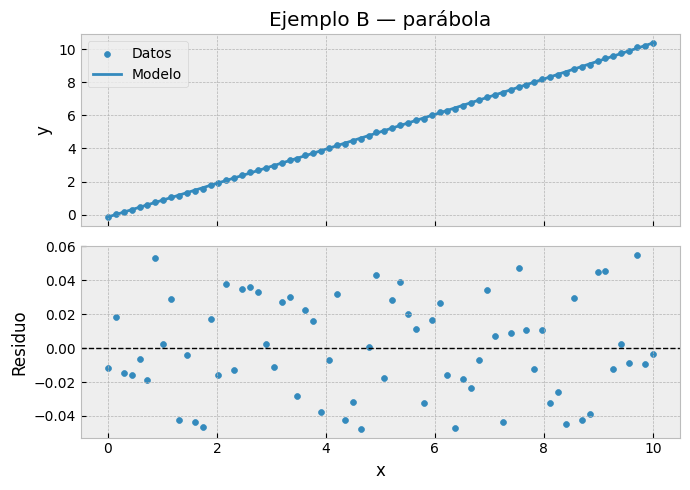

Suma r² — recta: 0.1430130242618172
Suma r² — parábola: 0.05921197667322688


In [3]:
x2, y2 = np.genfromtxt('ejemplo-s11b.txt').T
coef1 = np.polyfit(x2, y2, 1)
res_recta = graficar_ajuste(x2, y2, lambda z: np.polyval(coef1, z), 'Ejemplo B — recta')
coef2 = np.polyfit(x2, y2, 2)
res_parabola = graficar_ajuste(x2, y2, lambda z: np.polyval(coef2, z), 'Ejemplo B — parábola')
print('Suma r² — recta:', np.sum(res_recta**2))
print('Suma r² — parábola:', np.sum(res_parabola**2))

## 3. Ejemplo C — tendencia oscilatoria en residuos
En el notebook de clase se propone $f(x)=c_0+c_1x+c_2\cos(c_3x+c_4)$. Comprobamos si los residuos revelan una oscilación discernible.

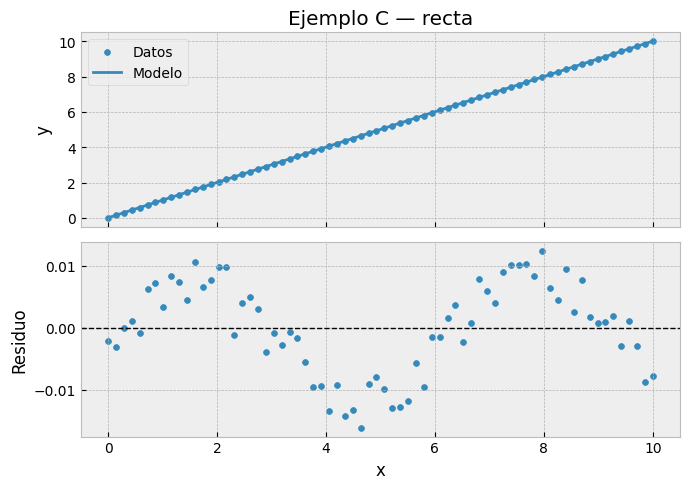

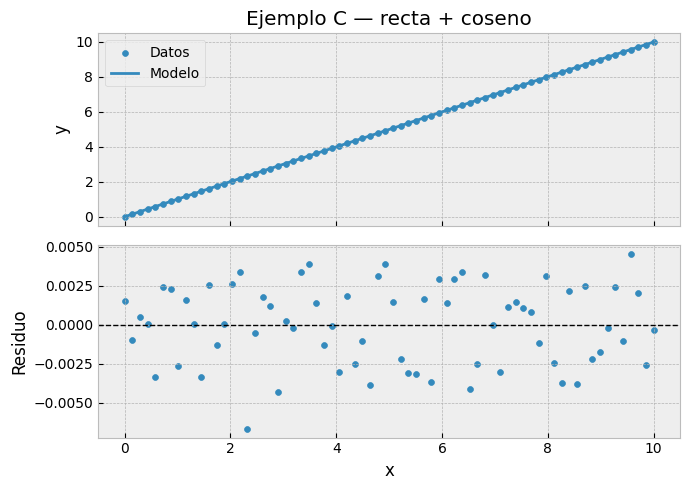

Suma r² (recta / recta + coseno): 0.0038245163705849803 0.0004528389331043714


In [4]:
x3, y3 = np.genfromtxt('ejemplo-s11c.txt').T
c_lineal = np.polyfit(x3, y3, 1)
r_lineal = graficar_ajuste(x3, y3, lambda z: np.polyval(c_lineal, z), 'Ejemplo C — recta')

def modelo_osc(x, c0, c1, c2, c3, c4):
    return c0 + c1*x + c2*np.cos(c3*x + c4)

# Es necesario un punto inicial razonable para un ajuste no lineal.
p0 = [0, 1, 0.01, 2*np.pi/6, 0]  # periodo inicial ~6 en x
param, cov = curve_fit(modelo_osc, x3, y3, p0=p0, maxfev=10000)
r_osc = graficar_ajuste(x3, y3, lambda z: modelo_osc(z, *param), 'Ejemplo C — recta + coseno')
print('Suma r² (recta / recta + coseno):', np.sum(r_lineal**2), np.sum(r_osc**2))

**Comprueba:** si los residuos tienen un patrón reconocible, ¿qué sugiere sobre el modelo? ¿Que el ajuste más flexible disminuya $\sum r_i^2$ demuestra que el nuevo término esté físicamente justificado?